# Fraud Detection Model Training

This notebook walks through the full model-building process:
1. Load & inspect data
2. Simulate velocity counters (replaying CSV chronologically)
3. Combine all features
4. Time-based train/test split
5. Handle class imbalance
6. Train RandomForest + XGBoost
7. Evaluate both models
8. Save the best model

**Run cells one at a time** — each section builds on the previous.

## Section 1 — Load & Inspect Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import bisect

# Run this notebook from the project root: jupyter notebook
df = pd.read_csv("../app/data/Fraud_Data.csv")
df["signup_time"] = pd.to_datetime(df["signup_time"])
df["purchase_time"] = pd.to_datetime(df["purchase_time"])

# CRITICAL: sort by purchase_time before doing anything else.
# Velocity features look backward in time — if we don't sort first,
# we'd be computing features using "future" transactions.
df = df.sort_values("purchase_time").reset_index(drop=True)

print(f"Rows: {len(df):,}")
print(f"Date range: {df['purchase_time'].min()} → {df['purchase_time'].max()}")
df.head()

Rows: 151,112
Date range: 2015-01-01 00:00:44 → 2015-12-16 02:56:05


,user_id,signup_time,purchase_time,purchase_value,device_id,source,browser,sex,age,ip_address,class
0,309557,2015-01-01 00:00:43,2015-01-01 00:00:44,14,BBPACGBUVJUXF,Ads,Chrome,F,38,2.001426e+09,1
1,124539,2015-01-01 00:00:44,2015-01-01 00:00:45,14,BBPACGBUVJUXF,Ads,Chrome,F,38,2.001426e+09,1
2,161246,2015-01-01 00:00:45,2015-01-01 00:00:46,14,BBPACGBUVJUXF,Ads,Chrome,F,38,2.001426e+09,1
3,356414,2015-01-01 00:00:46,2015-01-01 00:00:47,14,BBPACGBUVJUXF,Ads,Chrome,F,38,2.001426e+09,1
4,338656,2015-01-01 00:00:47,2015-01-01 00:00:48,14,BBPACGBUVJUXF,Ads,Chrome,F,38,2.001426e+09,1


In [2]:
# Load IP→country lookup table from CSV using binary search (O(log n) per lookup).
# Same bisect approach as the velocity simulation — no PostgreSQL needed here.
ip_csv = pd.read_csv("../app/data/IpAddress_to_Country.csv")
_ip_from = ip_csv["lower_bound_ip_address"].values  # already sorted ascending
_ip_to   = ip_csv["upper_bound_ip_address"].values
_ip_ctry = ip_csv["country"].values

def lookup_ip_country(ip_float):
    if pd.isna(ip_float):
        return "Unknown"
    ip_int = int(ip_float)
    idx = bisect.bisect_right(_ip_from, ip_int) - 1
    if idx >= 0 and ip_int <= _ip_to[idx]:
        return _ip_ctry[idx]
    return "Unknown"

df["ip_country"] = df["ip_address"].apply(lookup_ip_country)
print(f"IP country lookup done. Top countries:")
print(df["ip_country"].value_counts().head(10))

IP country lookup done. Top countries:
ip_country
United States        58049
Unknown              21966
China                12038
Japan                 7306
United Kingdom        4490
Korea Republic of     4162
Germany               3646
France                3161
Canada                2975
Brazil                2961
Name: count, dtype: int64


class
0    136961
1     14151
Name: count, dtype: int64

Fraud rate: 9.4%


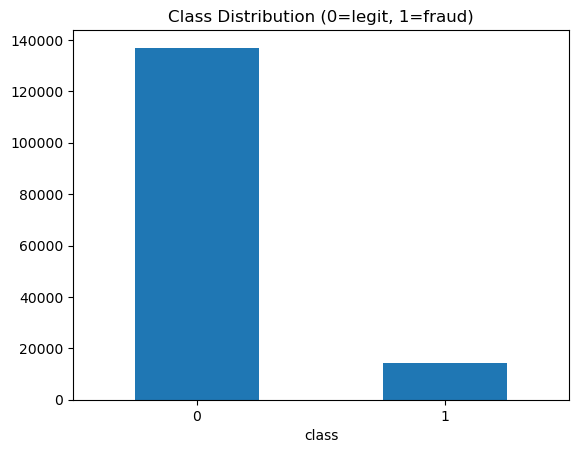

In [3]:
# Check class balance — fraud detection datasets are almost always imbalanced
counts = df["class"].value_counts()
print(counts)
print(f"\nFraud rate: {counts[1] / len(df) * 100:.1f}%")

counts.plot(kind="bar", title="Class Distribution (0=legit, 1=fraud)")
plt.xticks(rotation=0)
plt.show()

In [4]:
# Quick look at raw feature distributions
df[["purchase_value", "age"]].describe()

,purchase_value,age
count,151112.000000,151112.000000
mean,36.935372,33.140704
std,18.322762,8.617733
min,9.000000,18.000000
25%,22.000000,27.000000
50%,35.000000,33.000000
75%,49.000000,39.000000
max,154.000000,76.000000


In [5]:
# Categorical columns
for col in ["source", "browser", "sex"]:
    print(f"\n{col}:")
    print(df[col].value_counts())


source:
source
SEO       60615
Ads       59881
Direct    30616
Name: count, dtype: int64

browser:
browser
Chrome     61432
IE         36727
Safari     24667
FireFox    24610
Opera       3676
Name: count, dtype: int64

sex:
sex
M    88293
F    62819
Name: count, dtype: int64


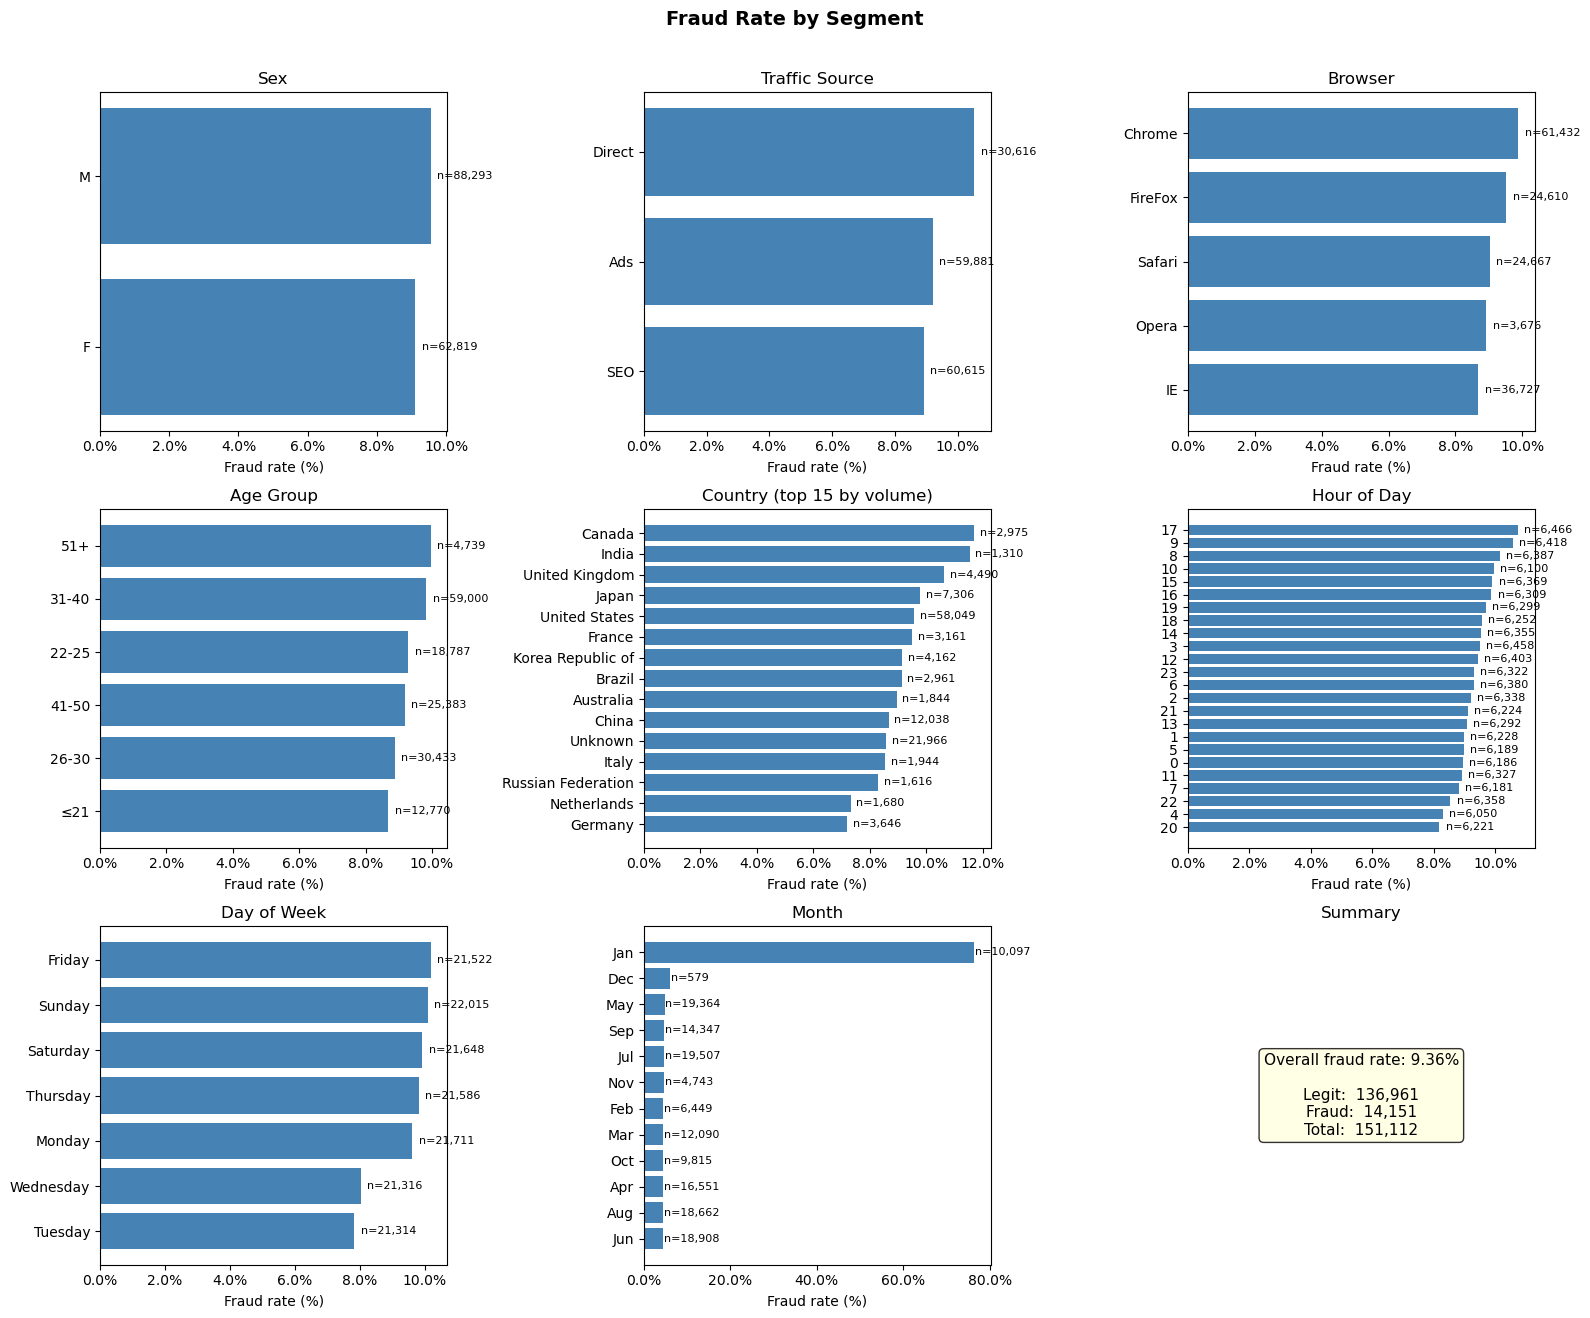

In [6]:
# Fraud rate by segment — one bar chart per categorical variable.
# This helps confirm that each feature carries a real signal before training.
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

def fraud_rate_chart(ax, series, label, top_n=None):
    """Plot fraud rate (%) per segment, sorted descending, with count annotations."""
    grp = df.groupby(series)['class'].agg(['mean', 'count'])
    grp['mean'] *= 100
    if top_n:
        grp = grp.nlargest(top_n, 'count')
    grp = grp.sort_values('mean', ascending=True)
    bars = ax.barh(grp.index.astype(str), grp['mean'], color='steelblue')
    for bar, (_, row) in zip(bars, grp.iterrows()):
        ax.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height() / 2,
                f"n={int(row['count']):,}", va='center', fontsize=8)
    ax.set_xlabel('Fraud rate (%)')
    ax.set_title(label)
    ax.xaxis.set_major_formatter(mticker.FormatStrFormatter('%.1f%%'))

# Bin raw age into readable groups for the chart
df['age_bin'] = pd.cut(df['age'],
    bins=[0, 21, 25, 30, 40, 50, 120],
    labels=['≤21', '22-25', '26-30', '31-40', '41-50', '51+'])

# Temporal segments derived from purchase_time
df['hour_bin']  = df['purchase_time'].dt.hour
df['dow_bin']   = df['purchase_time'].dt.day_name()
df['month_bin'] = df['purchase_time'].dt.strftime('%b')

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
fig.suptitle('Fraud Rate by Segment', fontsize=14, fontweight='bold', y=1.01)

fraud_rate_chart(axes[0, 0], df['sex'],          'Sex')
fraud_rate_chart(axes[0, 1], df['source'],        'Traffic Source')
fraud_rate_chart(axes[0, 2], df['browser'],       'Browser')
fraud_rate_chart(axes[1, 0], df['age_bin'],       'Age Group')
fraud_rate_chart(axes[1, 1], df['ip_country'],    'Country (top 15 by volume)', top_n=15)
fraud_rate_chart(axes[1, 2], df['hour_bin'],      'Hour of Day')
fraud_rate_chart(axes[2, 0], df['dow_bin'],       'Day of Week')
fraud_rate_chart(axes[2, 1], df['month_bin'],     'Month')
fraud_rate_chart(axes[2, 2], df['age_bin'],       'Age Group (repeat for ref)')

# Hide the duplicate panel — replace with overall summary table
axes[2, 2].clear()
axes[2, 2].axis('off')
overall = df.groupby('class').size().rename({0: 'Legit', 1: 'Fraud'})
summary_text = (
    f"Overall fraud rate: {df['class'].mean()*100:.2f}%\n\n"
    f"Legit:  {overall.get('Legit', 0):,}\n"
    f"Fraud:  {overall.get('Fraud', 0):,}\n"
    f"Total:  {len(df):,}"
)
axes[2, 2].text(0.5, 0.5, summary_text, ha='center', va='center',
                fontsize=11, transform=axes[2, 2].transAxes,
                bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))
axes[2, 2].set_title('Summary')

plt.tight_layout()
plt.show()

# Drop the temporary columns we added for charting only
df.drop(columns=['age_bin', 'hour_bin', 'dow_bin', 'month_bin'], inplace=True)


In [7]:
from collections import defaultdict
import bisect
from tqdm import tqdm

# Running sorted history per entity
did_uid_times = defaultdict(list)
did_uid_users = defaultdict(list)
uid_did_times = defaultdict(list)
uid_did_devs  = defaultdict(list)
ip_uid_times  = defaultdict(list)
ip_uid_users  = defaultdict(list)
pur_all_times = defaultdict(list)
pur_all_vals  = defaultdict(list)
pur_suc_times = defaultdict(list)
pur_suc_vals  = defaultdict(list)
did_txn_times = defaultdict(list)   # device_id -> [all transaction timestamps, no dedup]
uid_last_ts:  dict = {}             # user_id -> timestamp of most recent transaction
did_first_seen = {}                 # (device_id, user_id) -> first purchase_time
country_txn_times = defaultdict(list)  # ip_country -> [timestamps of all transactions]

WINDOWS = {
    "5min":  5  * 60,
    "10min": 10 * 60,
    "1h":    1  * 3600,
    "2h":  2  * 3600,
    "24h": 24 * 3600,
    "7d":  7  * 86400,
    "30d": 30 * 86400,
    "90d": 90 * 86400,
}

def count_distinct_in_window(times_list, vals_list, cutoff_ts):
    """Count distinct values in times_list that are >= cutoff_ts."""
    idx = bisect.bisect_left(times_list, cutoff_ts)
    return len(set(vals_list[idx:]))

def count_and_sum_in_window(times_list, vals_list, cutoff_ts):
    """Count entries and sum values in times_list >= cutoff_ts."""
    idx = bisect.bisect_left(times_list, cutoff_ts)
    vals = vals_list[idx:]
    return len(vals), sum(vals)

def median_in_window(times_list, vals_list, cutoff_ts):
    """Return median of vals in times_list that are >= cutoff_ts.
    Returns 0.0 if no prior transactions exist in the window."""
    idx = bisect.bisect_left(times_list, cutoff_ts)
    vals = vals_list[idx:]
    if not vals:
        return 0.0
    return float(np.median(vals))

def count_in_window(times_list, cutoff_ts):
    """Count entries in times_list that are >= cutoff_ts."""
    idx = bisect.bisect_left(times_list, cutoff_ts)
    return len(times_list) - idx

print("Helper functions defined. Ready to simulate.")

Helper functions defined. Ready to simulate.


In [8]:
# This cell takes ~2-4 minutes for 151k rows.
rows = []

for _, row in tqdm(df.iterrows(), total=len(df), desc="Simulating velocity"):
    ts  = row["purchase_time"].timestamp()
    uid = str(row["user_id"])
    did = str(row["device_id"])
    ip  = row["ip_address"]
    val = row["purchase_value"]
    country = row["ip_country"]
    is_fraud = row["class"]

    feat = {}

    # --- did_uid: distinct users seen on this device ---
    for w in ["5min", "10min", "1h", "2h", "24h", "7d", "30d", "90d"]:
        feat[f"did_uid_{w}"] = count_distinct_in_window(
            did_uid_times[did], did_uid_users[did], ts - WINDOWS[w])

    # --- uid_did: distinct devices seen for this user ---
    for w in ["5min", "10min", "1h", "2h", "24h", "7d", "30d", "90d"]:
        feat[f"uid_did_{w}"] = count_distinct_in_window(
            uid_did_times[uid], uid_did_devs[uid], ts - WINDOWS[w])

    # --- ip_uid: distinct users seen from this IP (2h, 24h, 7d only) ---
    for w in ["5min", "10min", "1h", "2h", "24h", "7d"]:
        feat[f"ip_uid_{w}"] = count_distinct_in_window(
            ip_uid_times[ip], ip_uid_users[ip], ts - WINDOWS[w])

    # --- purchase counts & amounts (all transactions) ---
    for w in ["5min", "10min", "1h", "24h", "7d", "30d", "90d"]:
        cnt, amt = count_and_sum_in_window(
            pur_all_times[uid], pur_all_vals[uid], ts - WINDOWS[w])
        feat[f"purchase_cnt_{w}"] = cnt
        feat[f"purchase_amt_{w}"] = amt

    # --- purchase counts & amounts (successful only: class=0 as proxy) ---
    for w in ["5min", "10min", "1h", "24h", "7d", "30d", "90d"]:
        cnt, amt = count_and_sum_in_window(
            pur_suc_times[uid], pur_suc_vals[uid], ts - WINDOWS[w])
        feat[f"purchase_success_cnt_{w}"] = cnt
        feat[f"purchase_success_amt_{w}"] = amt

    # --- did_uid_days_on_file ---
    key = (did, uid)
    if key not in did_first_seen:
        did_first_seen[key] = row["purchase_time"]
        feat["did_uid_days_on_file"] = 0
    else:
        feat["did_uid_days_on_file"] = (row["purchase_time"] - did_first_seen[key]).days

    # --- Median purchase amount in last 90d (uid-keyed) ---
    feat["pur_median_amt_90d"] = median_in_window(
        pur_all_times[uid], pur_all_vals[uid], ts - WINDOWS["90d"])

    # --- Transaction count for this device across windows (all txns, no dedup) ---
    for w in ["5min", "10min", "1h", "2h", "24h", "7d", "30d"]:
        idx = bisect.bisect_left(did_txn_times[did], ts - WINDOWS[w])
        feat[f"did_txn_cnt_{w}"] = len(did_txn_times[did]) - idx

    # --- Time since this user's last transaction (0 = first-ever transaction) ---
    feat["time_since_last_txn_uid"] = ts - uid_last_ts.get(uid, ts)

    # --- Country-level transaction counts (24h, 7d, 30d) ---
    # Counts how many transactions from this country were seen before this one.
    # High values signal geographic fraud clusters.
    for w in ["5min", "10min", "1h", "24h", "7d", "30d"]:
        feat[f"country_txn_count_{w}"] = count_in_window(
            country_txn_times[country], ts - WINDOWS[w])

    rows.append(feat)

    # Append to history AFTER computing features — transaction must not see itself
    did_uid_times[did].append(ts);  did_uid_users[did].append(uid)
    uid_did_times[uid].append(ts);  uid_did_devs[uid].append(did)
    ip_uid_times[ip].append(ts);    ip_uid_users[ip].append(uid)
    pur_all_times[uid].append(ts);  pur_all_vals[uid].append(val)
    did_txn_times[did].append(ts)
    uid_last_ts[uid] = ts
    country_txn_times[country].append(ts)
    if is_fraud == 0:
        pur_suc_times[uid].append(ts)
        pur_suc_vals[uid].append(val)

vel_df = pd.DataFrame(rows)
print(f"Velocity simulation done. Shape: {vel_df.shape}")
vel_df.head()

Simulating velocity: 100%|███████████| 151112/151112 [00:05<00:00, 28458.55it/s]


Velocity simulation done. Shape: (151112, 66)


,did_uid_5min,did_uid_10min,did_uid_1h,did_uid_2h,did_uid_24h,did_uid_7d,did_uid_30d,did_uid_90d,uid_did_5min,uid_did_10min,...,did_txn_cnt_24h,did_txn_cnt_7d,did_txn_cnt_30d,time_since_last_txn_uid,country_txn_count_5min,country_txn_count_10min,country_txn_count_1h,country_txn_count_24h,country_txn_count_7d,country_txn_count_30d
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0.0,0,0,0,0,0,0
1,1,1,1,1,1,1,1,1,0,0,...,1,1,1,0.0,1,1,1,1,1,1
2,2,2,2,2,2,2,2,2,0,0,...,2,2,2,0.0,2,2,2,2,2,2
3,3,3,3,3,3,3,3,3,0,0,...,3,3,3,0.0,3,3,3,3,3,3
4,4,4,4,4,4,4,4,4,0,0,...,4,4,4,0.0,4,4,4,4,4,4


In [9]:
# Raw transaction features
# Categorical columns (sex, source, browser) are label-encoded: each unique string
# gets an integer. Tree models (RF, XGBoost) don't need one-hot encoding.
# Missing values are filled with -1 so the model can distinguish "missing" from 0.

ip_country_cat = pd.Categorical(df["ip_country"])

feat_raw = pd.DataFrame({
    "purchase_value":    df["purchase_value"],
    "days_since_signup": (df["purchase_time"] - df["signup_time"]).dt.days
                         .fillna(-999).astype(int),
    "sex":               df["sex"].map({"M": 0, "F": 1}).fillna(-1).astype(int),
    "source":            pd.Categorical(df["source"]).codes,
    "browser":           pd.Categorical(df["browser"]).codes,
    "ip_country_code":   ip_country_cat.codes,  # int; -1 = Unknown
    "hour_of_day":       df["purchase_time"].dt.hour,
    # Account age bin: 0=0-7d, 1=8-14d, 2=15-30d, 3=31-90d,
    #                  4=91-180d, 5=181-360d, 6=361-720d, 7=720+d
    # -999 sentinel (missing signup_time) is clipped to 0 → treated as brand-new.
    "days_since_signup_group": pd.cut(
        pd.Series(
            (df["purchase_time"] - df["signup_time"]).dt.days.fillna(0).clip(lower=0)
        ),
        bins=[-0.5, 7, 14, 30, 90, 180, 360, 720, float("inf")],
        labels=False,
    ).astype(int),
    "day_of_week":       df["purchase_time"].dt.dayofweek,  # 0=Monday, 6=Sunday
    "month_of_year":     df["purchase_time"].dt.month,
})

X = pd.concat([feat_raw.reset_index(drop=True), vel_df], axis=1)
y = df["class"]

print(f"Feature matrix shape: {X.shape}")
print(f"\nFeature columns ({len(X.columns)}):")
print(list(X.columns))

Feature matrix shape: (151112, 76)

Feature columns (76):
['purchase_value', 'days_since_signup', 'sex', 'source', 'browser', 'ip_country_code', 'hour_of_day', 'days_since_signup_group', 'day_of_week', 'month_of_year', 'did_uid_5min', 'did_uid_10min', 'did_uid_1h', 'did_uid_2h', 'did_uid_24h', 'did_uid_7d', 'did_uid_30d', 'did_uid_90d', 'uid_did_5min', 'uid_did_10min', 'uid_did_1h', 'uid_did_2h', 'uid_did_24h', 'uid_did_7d', 'uid_did_30d', 'uid_did_90d', 'ip_uid_5min', 'ip_uid_10min', 'ip_uid_1h', 'ip_uid_2h', 'ip_uid_24h', 'ip_uid_7d', 'purchase_cnt_5min', 'purchase_amt_5min', 'purchase_cnt_10min', 'purchase_amt_10min', 'purchase_cnt_1h', 'purchase_amt_1h', 'purchase_cnt_24h', 'purchase_amt_24h', 'purchase_cnt_7d', 'purchase_amt_7d', 'purchase_cnt_30d', 'purchase_amt_30d', 'purchase_cnt_90d', 'purchase_amt_90d', 'purchase_success_cnt_5min', 'purchase_success_amt_5min', 'purchase_success_cnt_10min', 'purchase_success_amt_10min', 'purchase_success_cnt_1h', 'purchase_success_amt_1h', 'pu

In [11]:
# --- Derived features ---
# These combine raw and velocity columns into higher-level signals.

# How does this purchase compare to the user's recent average spend?
# A value >> 1 means the transaction is unusually large for this user.
# .clip(lower=1) on the denominator avoids division by zero.
user_avg_amt_30d = X["purchase_amt_30d"] / X["purchase_cnt_30d"].clip(lower=1)
X["amount_vs_user_avg_30d"] = X["purchase_value"] / user_avg_amt_30d.clip(lower=1)

# Customer age minus account tenure in years.
# A large positive gap means the account was opened recently relative to age —
# a potential signal for synthetic or stolen-identity accounts.
#X["age_account_gap"] = X["age"] - X["days_since_signup"] / 365

# Binary flag: is this purchase > 2x the user's median spend over the past 90 days?
# 0 when there is no prior history (pur_median_amt_90d == 0 -> first-time buyer, not flagged).
X["high_amount_vs_hist"] = (
    (X["pur_median_amt_90d"] > 0) &
    (X["purchase_value"] > 2 * X["pur_median_amt_90d"])
).astype(int)

print("Derived features added: amount_vs_user_avg_30d, device_txn_rate_1h, high_amount_vs_hist")
print(f"Feature matrix shape: {X.shape}")
print(f"high_amount_vs_hist value counts:")
print(X["high_amount_vs_hist"].value_counts())


Derived features added: amount_vs_user_avg_30d, device_txn_rate_1h, high_amount_vs_hist
Feature matrix shape: (151112, 78)
high_amount_vs_hist value counts:
high_amount_vs_hist
0    151112
Name: count, dtype: int64


In [12]:
# Sanity check: no NaN values (tree models can handle NaN in XGBoost
# but RandomForest cannot)
print("NaN counts per column:")
print(X.isna().sum()[X.isna().sum() > 0])
print("(empty = no NaNs, good!)")

NaN counts per column:
Series([], dtype: int64)
(empty = no NaNs, good!)


/opt/homebrew/Caskroom/miniconda/base/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/opt/homebrew/Caskroom/miniconda/base/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


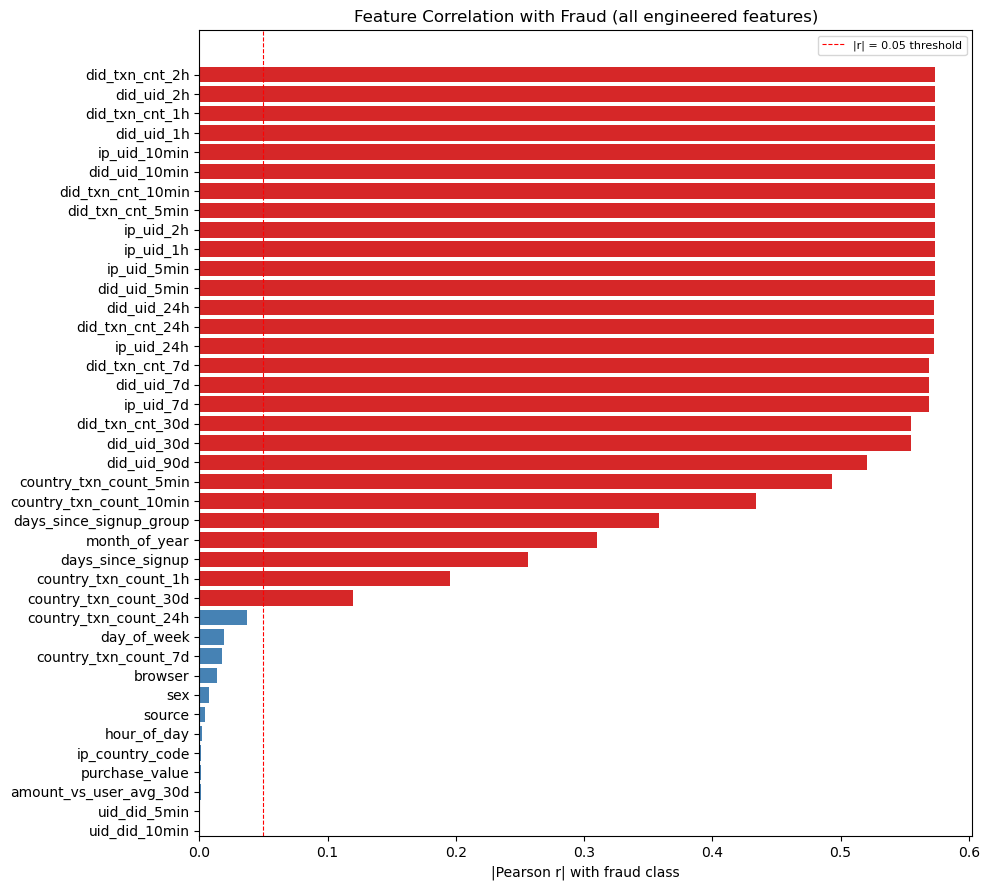

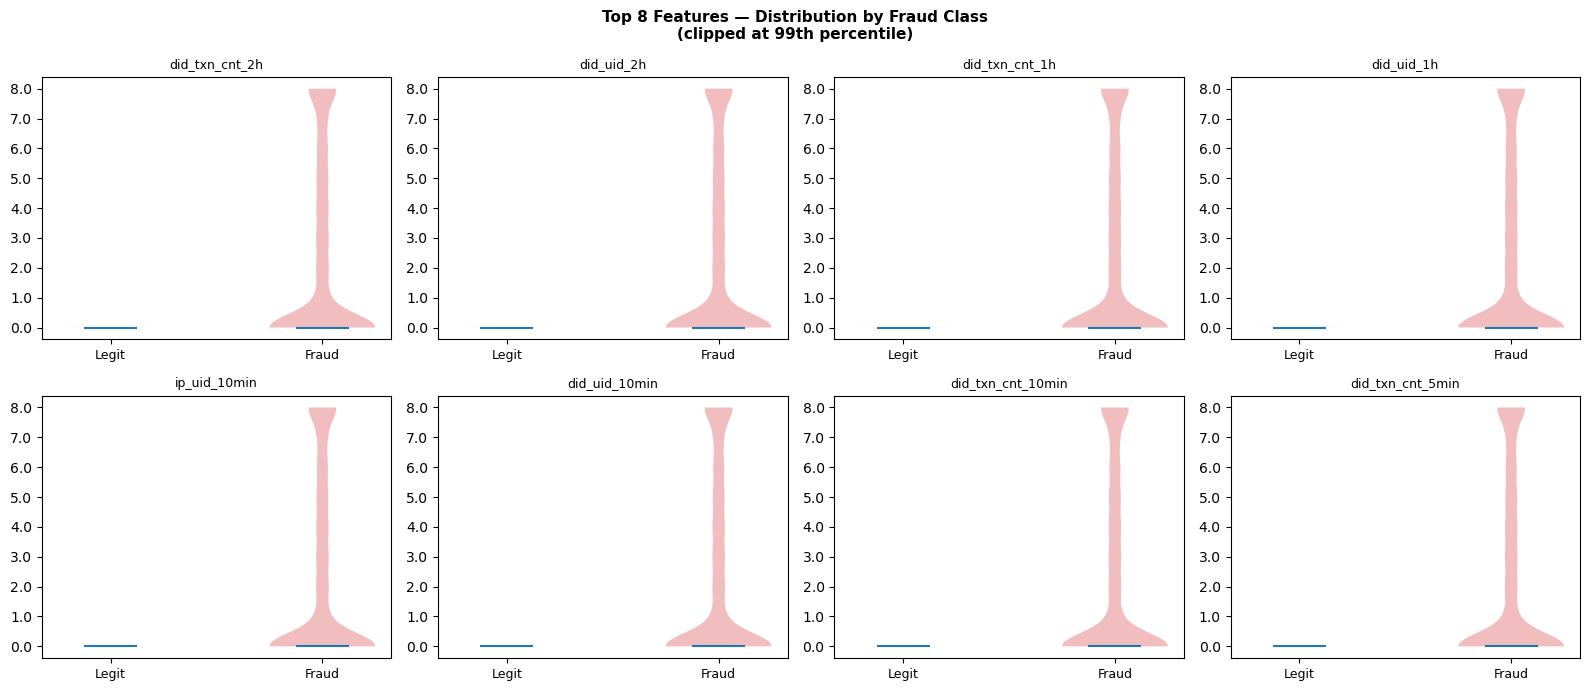

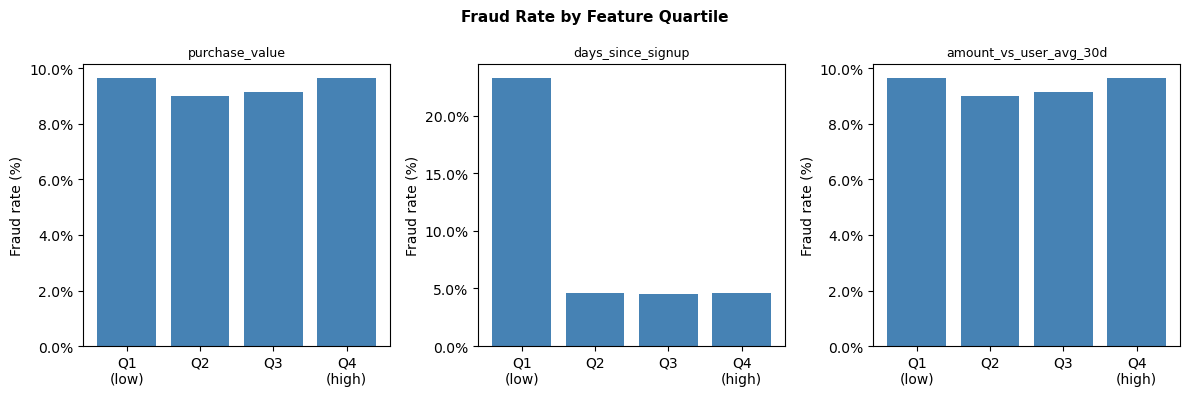

In [13]:
# Fraud rates by engineered feature — shows which velocity/derived features
# best separate fraud from legit transactions before any model is trained.
#
# Two views:
#   1. Correlation bar chart — how linearly related each feature is to fraud (quick overview)
#   2. Violin plots — distribution shape of the top 8 most discriminative features by class

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

# --- 1. Point-biserial correlation of every feature with fraud class ---
corr = X.corrwith(y.reset_index(drop=True)).abs().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 9))
colors = ['#d62728' if corr[f] > 0.05 else 'steelblue' for f in corr.index]
ax.barh(corr.index[::-1], corr.values[::-1], color=colors[::-1])
ax.axvline(0.05, color='red', linestyle='--', linewidth=0.8, label='|r| = 0.05 threshold')
ax.set_xlabel('|Pearson r| with fraud class')
ax.set_title('Feature Correlation with Fraud (all engineered features)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# --- 2. Violin plots: fraud vs legit distribution for top 8 features ---
top_feats = corr.head(8).index.tolist()

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

for ax, feat in zip(axes, top_feats):
    legit = X.loc[y == 0, feat].clip(upper=X[feat].quantile(0.99))
    fraud = X.loc[y == 1, feat].clip(upper=X[feat].quantile(0.99))
    parts = ax.violinplot([legit, fraud], positions=[0, 1],
                          showmedians=True, showextrema=False)
    parts['bodies'][0].set_facecolor('steelblue')
    parts['bodies'][1].set_facecolor('#d62728')
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Legit', 'Fraud'], fontsize=9)
    ax.set_title(feat, fontsize=9)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(
        lambda x, _: f'{x:,.0f}' if x >= 1000 else f'{x:.1f}'))

plt.suptitle('Top 8 Features — Distribution by Fraud Class\n(clipped at 99th percentile)',
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

# --- 3. Fraud rate by quartile for well-distributed features ---
# Velocity features are sparse (mostly 0), so we pick features guaranteed
# to have good spread across all rows.
quartile_candidates = [
    'purchase_value', 'days_since_signup', 'amount_vs_user_avg_30d',
    'age_account_gap', 'pur_median_amt_90d', 'did_uid_days_on_file',
    'time_since_last_txn_uid',
]
# Only keep candidates that actually produce >= 2 distinct quartile bins
def has_enough_bins(feat, min_bins=2):
    try:
        _, edges = pd.qcut(X[feat], q=4, duplicates='drop', retbins=True)
        return len(edges) - 1 >= min_bins
    except Exception:
        return False

cont_feats = [f for f in quartile_candidates if f in X.columns and has_enough_bins(f)][:5]

fig, axes = plt.subplots(1, len(cont_feats), figsize=(4 * len(cont_feats), 4))
if len(cont_feats) == 1:
    axes = [axes]

for ax, feat in zip(axes, cont_feats):
    tmp = X[[feat]].copy()
    tmp['fraud'] = y.values
    _, bin_edges = pd.qcut(tmp[feat], q=4, duplicates='drop', retbins=True)
    n_bins = len(bin_edges) - 1
    qlabels = [f'Q{i+1}' for i in range(n_bins)]
    qlabels[0] += '\n(low)'; qlabels[-1] += '\n(high)'
    tmp['quartile'] = pd.qcut(tmp[feat], q=4, duplicates='drop', labels=qlabels)
    rates = tmp.groupby('quartile', observed=True)['fraud'].mean() * 100
    ax.bar(rates.index.astype(str), rates.values, color='steelblue')
    ax.set_title(feat, fontsize=9)
    ax.set_ylabel('Fraud rate (%)')
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.1f%%'))

plt.suptitle('Fraud Rate by Feature Quartile',
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()


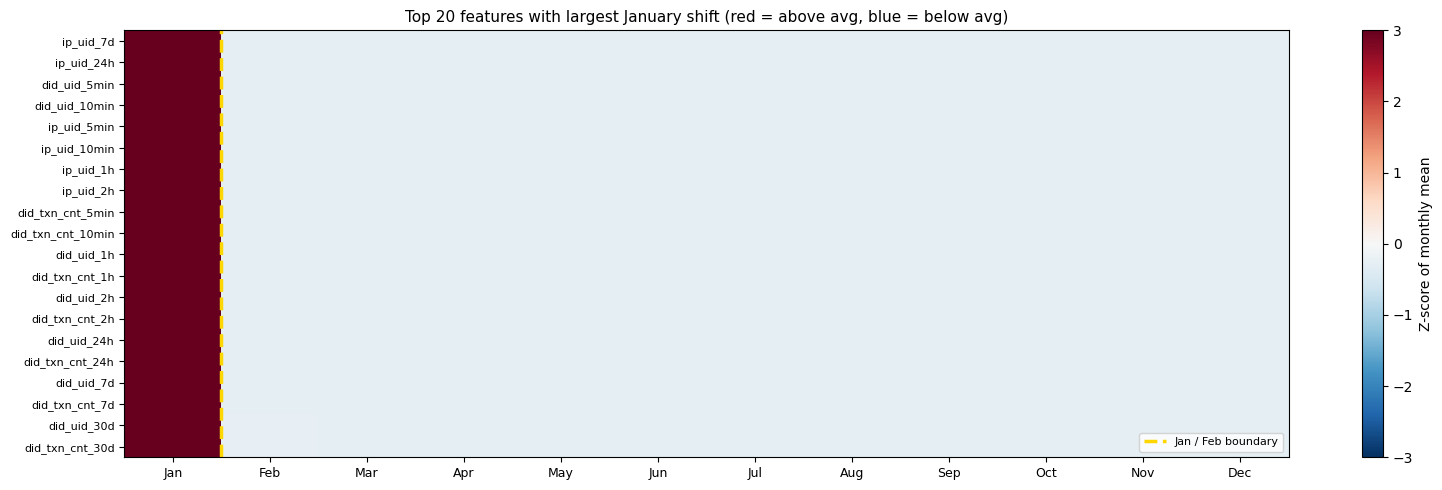

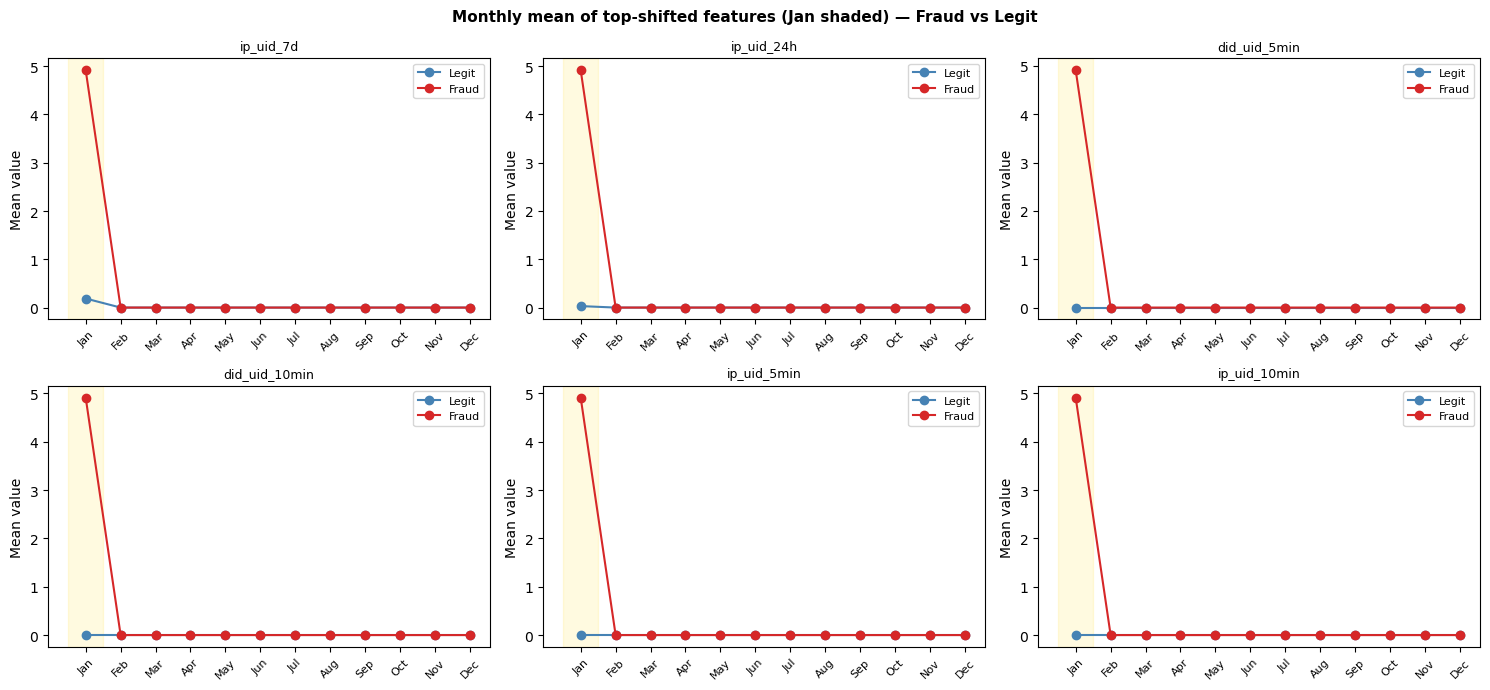

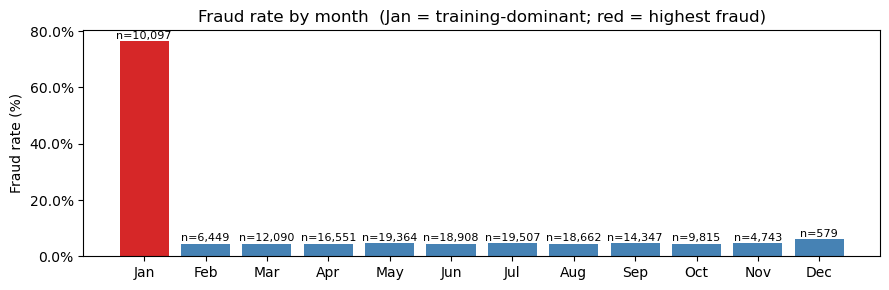

In [14]:
# Feature distribution by month — identifies which features shift between January
# (fraud-heavy training period) and later months (quieter test period).
# Features with large January vs rest-of-year gaps explain why the model may
# behave differently in production compared to the training evaluation.

month_labels = {1:'Jan',2:'Feb',3:'Mar',4:'Apr',5:'May',6:'Jun',
                7:'Jul',8:'Aug',9:'Sep',10:'Oct',11:'Nov',12:'Dec'}

tmp = X.copy()
tmp['month']     = df['purchase_time'].dt.month
tmp['fraud']     = y.values
tmp['month_lbl'] = tmp['month'].map(month_labels)

months_present = sorted(tmp['month'].unique())
month_names    = [month_labels[m] for m in months_present]

# --- 1. Heatmap: z-scored feature mean by month (rows=months, cols=features) ---
# Z-score each feature so different magnitudes are comparable on the same colour scale.
monthly_means = tmp.groupby('month')[list(X.columns)].mean()
zscored = (monthly_means - monthly_means.mean()) / (monthly_means.std() + 1e-9)
zscored.index = [month_labels[m] for m in zscored.index]

# Sort features by their Jan-vs-rest deviation (largest shift first)
jan_deviation = (zscored.loc['Jan'] - zscored.drop('Jan').mean()).abs()
top_features  = jan_deviation.nlargest(20).index.tolist()

fig, ax = plt.subplots(figsize=(16, 5))
im = ax.imshow(zscored[top_features].T, aspect='auto', cmap='RdBu_r', vmin=-3, vmax=3)
ax.set_xticks(range(len(zscored.index)))
ax.set_xticklabels(zscored.index, fontsize=9)
ax.set_yticks(range(len(top_features)))
ax.set_yticklabels(top_features, fontsize=8)
ax.axvline(x=-0.5 + list(zscored.index).index('Jan') + 1,
           color='gold', linewidth=2.5, linestyle='--', label='Jan / Feb boundary')
plt.colorbar(im, ax=ax, label='Z-score of monthly mean')
ax.set_title('Top 20 features with largest January shift (red = above avg, blue = below avg)',
             fontsize=11)
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

# --- 2. Line plots: monthly mean for top 6 shifted features, fraud vs legit ---
top6 = jan_deviation.nlargest(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
axes = axes.flatten()

for ax, feat in zip(axes, top6):
    for label, grp_df, color in [(0, 'Legit', 'steelblue'), (1, 'Fraud', '#d62728')]:
        sub = tmp[tmp['fraud'] == label].groupby('month')[feat].mean()
        ax.plot([month_labels[m] for m in sub.index], sub.values,
                marker='o', label=grp_df, color=color)
    ax.axvspan(-0.5, 0.5, alpha=0.12, color='gold')   # shade Jan column
    ax.set_title(feat, fontsize=9)
    ax.set_ylabel('Mean value')
    ax.tick_params(axis='x', rotation=45, labelsize=8)
    ax.legend(fontsize=8)

plt.suptitle('Monthly mean of top-shifted features (Jan shaded) — Fraud vs Legit',
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

# --- 3. Fraud rate by month ---
fraud_by_month = tmp.groupby('month_lbl')['fraud'].agg(['mean','count'])
fraud_by_month = fraud_by_month.loc[[month_labels[m] for m in months_present]]
fraud_by_month['mean'] *= 100

fig, ax = plt.subplots(figsize=(9, 3))
bars = ax.bar(fraud_by_month.index, fraud_by_month['mean'],
              color=['#d62728' if m == 'Jan' else 'steelblue'
                     for m in fraud_by_month.index])
for bar, (_, row) in zip(bars, fraud_by_month.iterrows()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
            f"n={int(row['count']):,}", ha='center', va='bottom', fontsize=8)
ax.set_ylabel('Fraud rate (%)')
ax.set_title('Fraud rate by month  (Jan = training-dominant; red = highest fraud)')
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.1f%%'))
plt.tight_layout()
plt.show()

del tmp   # free memory


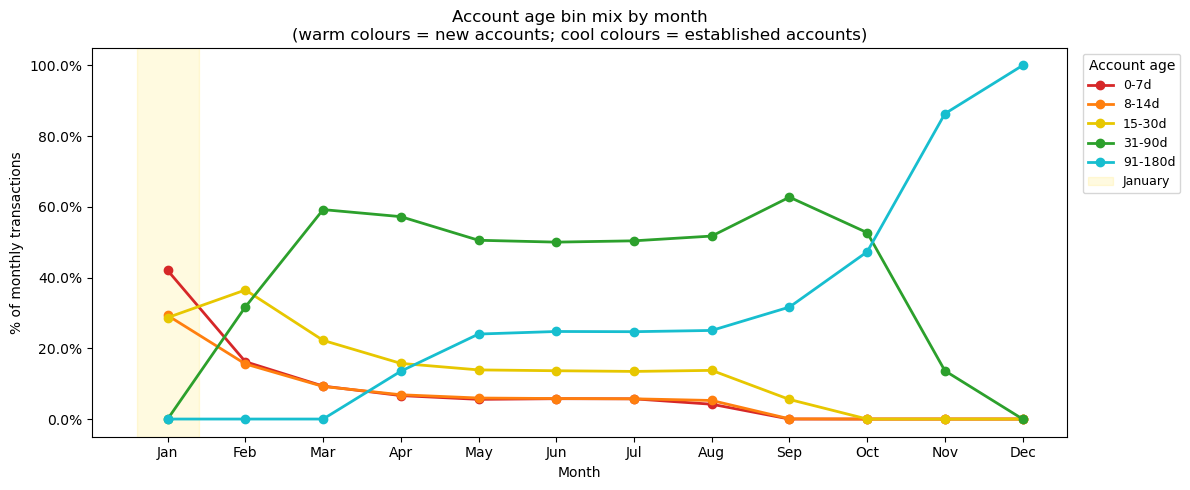

In [15]:
# Account age bin distribution by month — shows how the mix of new vs established
# accounts shifts over the year. New accounts (0-7 days) are a key fraud signal,
# so if January has an unusual concentration of new accounts it explains part of
# the high fraud rate seen in training data.

bins   = [0, 7, 14, 30, 90, 180, 360, 720, float('inf')]
labels = ['0-7d', '8-14d', '15-30d', '31-90d', '91-180d', '181-360d', '361-720d', '720+d']

tmp = pd.DataFrame({
    'days_since_signup': X['days_since_signup'].clip(lower=0),  # -999 sentinel -> 0 for binning
    'month': df['purchase_time'].dt.month,
})
tmp['month_lbl'] = tmp['month'].map(
    {1:'Jan',2:'Feb',3:'Mar',4:'Apr',5:'May',6:'Jun',
     7:'Jul',8:'Aug',9:'Sep',10:'Oct',11:'Nov',12:'Dec'})

tmp['age_bin'] = pd.cut(tmp['days_since_signup'], bins=bins, labels=labels, right=True)

# Percentage of transactions in each bin, per month
monthly_counts = (
    tmp.groupby(['month', 'age_bin'], observed=True)
       .size()
       .unstack(fill_value=0)
)
monthly_pct = monthly_counts.div(monthly_counts.sum(axis=1), axis=0) * 100

month_labels_ord = {1:'Jan',2:'Feb',3:'Mar',4:'Apr',5:'May',6:'Jun',
                    7:'Jul',8:'Aug',9:'Sep',10:'Oct',11:'Nov',12:'Dec'}
monthly_pct.index = [month_labels_ord[m] for m in monthly_pct.index]

# Colour palette: short tenures in warm colours, long tenures in cool colours
colors = ['#d62728','#ff7f0e','#e7c700','#2ca02c','#17becf','#1f77b4','#9467bd','#7f7f7f']

fig, ax = plt.subplots(figsize=(12, 5))
for col, color in zip(monthly_pct.columns, colors):
    ax.plot(monthly_pct.index, monthly_pct[col], marker='o', label=col,
            color=color, linewidth=2)

# Shade January
jan_idx = list(monthly_pct.index).index('Jan')
ax.axvspan(jan_idx - 0.4, jan_idx + 0.4, alpha=0.12, color='gold', label='January')

ax.set_ylabel('% of monthly transactions')
ax.set_xlabel('Month')
ax.set_title('Account age bin mix by month\n'
             '(warm colours = new accounts; cool colours = established accounts)')
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.1f%%'))
ax.legend(title='Account age', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

del tmp


In [16]:
# Feature type summary — lists every column in X split into categorical vs numerical.
# Categorical features will be embedded in the neural network;
# numerical features will be standardised before being passed to FC layers.

CAT_FEATURES = [
    # Label-encoded from raw strings (arbitrary integer, order is meaningless)
    "sex",                   # M=0, F=1, missing=-1
    "source",                # SEO / Ads / Direct
    "browser",               # Chrome / IE / Safari / FireFox / Opera
    "ip_country_code",       # pd.Categorical code of ip_country string

    # Temporal — cyclical ordinal (treated as categorical for embedding)
    "hour_of_day",           # 0-23
    "day_of_week",           # 0=Mon … 6=Sun
    "month_of_year",         # 1=Jan … 12=Dec

    # Binned ordinal — finite set of ordered integer codes
    "days_since_signup_group",  # 0-7: 0-7d / 8-14d / 15-30d / 31-90d / 91-180d / 181-360d / 361-720d / 720+d
    "high_amount_vs_hist",   # binary flag: purchase > 2× user's 90d median
]

NUM_FEATURES = [c for c in X.columns if c not in CAT_FEATURES]

print(f"Categorical features  ({len(CAT_FEATURES):>2}):")
for f in CAT_FEATURES:
    in_X = "✓" if f in X.columns else "✗ NOT IN X"
    print(f"  {f:<30} {in_X}")

print(f"\nNumerical features  ({len(NUM_FEATURES):>2}):")
for f in NUM_FEATURES:
    print(f"  {f}")

print(f"\nTotal features in X: {len(X.columns)}")

in_X      = set(X.columns)
listed    = set(CAT_FEATURES) | set(NUM_FEATURES)
unlisted  = in_X - listed       # in X but not in either list
not_in_X  = listed - in_X       # in a list but missing from X

if not_in_X:
    print(f"\n⚠ In feature lists but NOT in X (rerun cell [10]?):")
    for c in sorted(not_in_X): print(f"    {c}")
if unlisted:
    print(f"\n⚠ In X but not categorised:")
    for c in sorted(unlisted): print(f"    {c}")
if not not_in_X and not unlisted:
    print("\nAll columns accounted for. ✓")


Categorical features  ( 9):
  sex                            ✓
  source                         ✓
  browser                        ✓
  ip_country_code                ✓
  hour_of_day                    ✓
  day_of_week                    ✓
  month_of_year                  ✓
  days_since_signup_group        ✓
  high_amount_vs_hist            ✓

Numerical features  (69):
  purchase_value
  days_since_signup
  did_uid_5min
  did_uid_10min
  did_uid_1h
  did_uid_2h
  did_uid_24h
  did_uid_7d
  did_uid_30d
  did_uid_90d
  uid_did_5min
  uid_did_10min
  uid_did_1h
  uid_did_2h
  uid_did_24h
  uid_did_7d
  uid_did_30d
  uid_did_90d
  ip_uid_5min
  ip_uid_10min
  ip_uid_1h
  ip_uid_2h
  ip_uid_24h
  ip_uid_7d
  purchase_cnt_5min
  purchase_amt_5min
  purchase_cnt_10min
  purchase_amt_10min
  purchase_cnt_1h
  purchase_amt_1h
  purchase_cnt_24h
  purchase_amt_24h
  purchase_cnt_7d
  purchase_amt_7d
  purchase_cnt_30d
  purchase_amt_30d
  purchase_cnt_90d
  purchase_amt_90d
  purchase_success_cnt_

## Section 4 — Time-Based Train/Test Split

**Why NOT a random split?**  
Our velocity features look backward in time. If we split randomly, a test row from January
might have a training row from February in its "history" — the model would learn from future
information that won't exist in production. This is called **data leakage**.

By splitting at the 80th percentile of time, the test set only contains transactions that
happened after all training transactions. This mirrors real deployment.

In [18]:
X.drop(columns=['month_of_year', 'sex'], inplace=True)

In [33]:
X.columns

Index(['purchase_value', 'days_since_signup', 'source', 'browser',
       'ip_country_code', 'hour_of_day', 'days_since_signup_group',
       'day_of_week', 'did_uid_5min', 'did_uid_10min', 'did_uid_1h',
       'did_uid_2h', 'did_uid_24h', 'did_uid_7d', 'did_uid_30d', 'did_uid_90d',
       'uid_did_5min', 'uid_did_10min', 'uid_did_1h', 'uid_did_2h',
       'uid_did_24h', 'uid_did_7d', 'uid_did_30d', 'uid_did_90d',
       'ip_uid_5min', 'ip_uid_10min', 'ip_uid_1h', 'ip_uid_2h', 'ip_uid_24h',
       'ip_uid_7d', 'purchase_cnt_5min', 'purchase_amt_5min',
       'purchase_cnt_10min', 'purchase_amt_10min', 'purchase_cnt_1h',
       'purchase_amt_1h', 'purchase_cnt_24h', 'purchase_amt_24h',
       'purchase_cnt_7d', 'purchase_amt_7d', 'purchase_cnt_30d',
       'purchase_amt_30d', 'purchase_cnt_90d', 'purchase_amt_90d',
       'purchase_success_cnt_5min', 'purchase_success_amt_5min',
       'purchase_success_cnt_10min', 'purchase_success_amt_10min',
       'purchase_success_cnt_1h', 'purchas

In [19]:
split_idx = int(len(X) * 0.80)
split_time = df["purchase_time"].iloc[split_idx]

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"Split at: {split_time}")
print(f"Train: {len(X_train):,} rows | Test: {len(X_test):,} rows")
print(f"Train fraud rate: {y_train.mean()*100:.1f}%")
print(f"Test fraud rate:  {y_test.mean()*100:.1f}%")

Split at: 2015-08-30 15:18:56
Train: 120,889 rows | Test: 30,223 rows
Train fraud rate: 10.6%
Test fraud rate:  4.6%


## Section 5 — Handle Class Imbalance

With ~9% fraud, a model that always predicts "not fraud" gets ~91% accuracy — useless.
We need the model to weight fraud cases more heavily during training.

- **RandomForest:** `class_weight='balanced'` — sklearn computes weights automatically
- **XGBoost:** `scale_pos_weight=ratio` — weights the positive class by this factor

We skip SMOTE (synthetic oversampling) here because synthetic rows would have velocity
features that don't correspond to any real sequence of events.

In [20]:
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
ratio = neg / pos

print(f"Training set — legit: {neg:,} | fraud: {pos:,}")
print(f"Imbalance ratio: {ratio:.1f}:1")
print(f"XGBoost scale_pos_weight will be set to: {ratio:.1f}")

Training set — legit: 108,127 | fraud: 12,762
Imbalance ratio: 8.5:1
XGBoost scale_pos_weight will be set to: 8.5


## Section 6 — Train Both Models

In [21]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,    # 200 trees — more trees = more stable, diminishing returns after ~200
    max_depth=12,        # limit depth to avoid memorizing training data
    min_samples_leaf=50,
    class_weight="balanced",  # auto-reweight: each class gets total_samples / (n_classes * count)
    n_jobs=-1,           # use all CPU cores
    random_state=42,
)

print("Training RandomForest...")
rf.fit(X_train, y_train)
print("Done!")

Training RandomForest...
Done!


In [24]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=500,        # more trees than RF because each XGBoost tree is shallow
    max_depth=7,             # XGBoost works best with shallower trees
    learning_rate=0.02,       # how much each tree contributes; lower = more trees needed
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=ratio,  # weight the fraud class by the imbalance ratio
    eval_metric="aucpr",     # monitor PR-AUC (better for imbalanced data than AUC-ROC)
    random_state=42,
)

print("Training XGBoost (prints eval every 50 rounds)...")
xgb.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=50,
)
print("Done!")

Training XGBoost (prints eval every 50 rounds)...
[0]	validation_0-aucpr:0.09137
[50]	validation_0-aucpr:0.08672
[100]	validation_0-aucpr:0.08852
[150]	validation_0-aucpr:0.08948
[200]	validation_0-aucpr:0.08928
[250]	validation_0-aucpr:0.09043
[300]	validation_0-aucpr:0.09019
[350]	validation_0-aucpr:0.09033
[400]	validation_0-aucpr:0.09011
[450]	validation_0-aucpr:0.08990
[499]	validation_0-aucpr:0.08912
Done!


## Section 7 — Evaluate Both Models

**Key metrics for fraud detection:**
- **Precision** (of fraud predictions): when we call something fraud, how often are we right?
- **Recall** (of actual fraud): what fraction of real fraud do we catch?
- **PR-AUC** (area under the precision-recall curve): the best single number for imbalanced classification
- **ROC-AUC**: good for comparing models, but can be misleadingly high on imbalanced data

The confusion matrix shows:
- **True Positives (TP):** fraud correctly caught
- **False Positives (FP):** legitimate transactions wrongly blocked
- **False Negatives (FN):** fraud that slipped through

In [28]:
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, average_precision_score,
    ConfusionMatrixDisplay, PrecisionRecallDisplay,
)

results = {}

for name, model in [("RandomForest", rf), ("XGBoost", xgb)]:
    y_pred  = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    roc_auc = roc_auc_score(y_test, y_proba)
    pr_auc  = average_precision_score(y_test, y_proba)
    results[name] = {"roc_auc": roc_auc, "pr_auc": pr_auc, "model": model}

    print(f"\n{'='*40}")
    print(f"  {name}")
    print(f"{'='*40}")
    print(classification_report(y_test, y_pred, target_names=["legit", "fraud"]))
    print(f"ROC-AUC : {roc_auc:.4f}")
    print(f"PR-AUC  : {pr_auc:.4f}  ← primary metric")


  RandomForest
              precision    recall  f1-score   support

       legit       0.96      0.98      0.97     28834
       fraud       0.24      0.11      0.15      1389

    accuracy                           0.94     30223
   macro avg       0.60      0.55      0.56     30223
weighted avg       0.93      0.94      0.93     30223

ROC-AUC : 0.5563
PR-AUC  : 0.0849  ← primary metric

  XGBoost
              precision    recall  f1-score   support

       legit       0.96      0.98      0.97     28834
       fraud       0.23      0.13      0.16      1389

    accuracy                           0.94     30223
   macro avg       0.60      0.55      0.57     30223
weighted avg       0.93      0.94      0.93     30223

ROC-AUC : 0.5532
PR-AUC  : 0.0896  ← primary metric


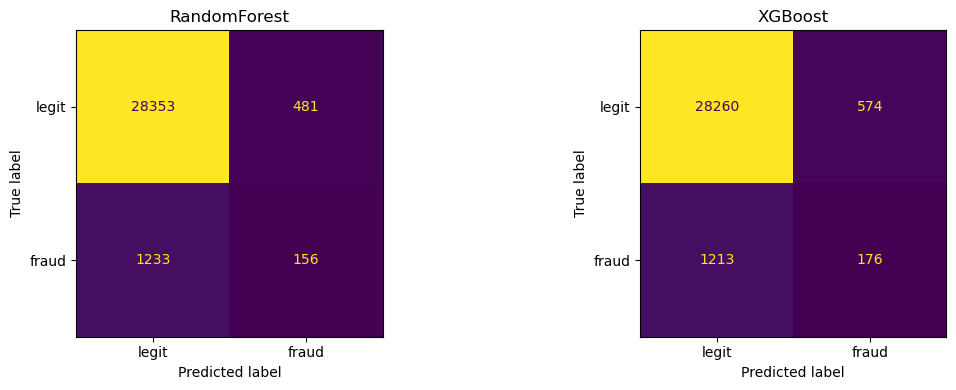

In [29]:
# Confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, model) in zip(axes, [("RandomForest", rf), ("XGBoost", xgb)]):
    cm = confusion_matrix(y_test, model.predict(X_test))
    disp = ConfusionMatrixDisplay(cm, display_labels=["legit", "fraud"])
    disp.plot(ax=ax, colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [30]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Set your desired threshold here. Run this cell to see the precision/recall trade-off,
# then adjust THRESHOLD and re-run the evaluation cell below.
# Higher threshold → higher precision (fewer legit transactions wrongly denied)
#                  → lower recall (more fraud slips through)
THRESHOLD = 0.5   # ← change this value, then re-run the evaluation cell above


print(f"{'Threshold':>10} {'Precision':>10} {'Recall':>10} {'F1':>8}")
print("-" * 42)
for t in np.arange(0.1, 0.95, 0.05):
    y_hat = (results["XGBoost"]["model"].predict_proba(X_test)[:, 1] >= t).astype(int)
    p = precision_score(y_test, y_hat, zero_division=0)
    r = recall_score(y_test, y_hat, zero_division=0)
    f = f1_score(y_test, y_hat, zero_division=0)
    marker = " ← selected" if abs(t - THRESHOLD) < 0.001 else ""
    print(f"{t:>10.2f} {p:>10.3f} {r:>10.3f} {f:>8.3f}{marker}")

 Threshold  Precision     Recall       F1
------------------------------------------
      0.10      0.046      1.000    0.088
      0.15      0.046      0.993    0.088
      0.20      0.046      0.897    0.088
      0.25      0.050      0.562    0.093
      0.30      0.077      0.250    0.118
      0.35      0.157      0.147    0.152
      0.40      0.220      0.132    0.165
      0.45      0.233      0.131    0.168
      0.50      0.235      0.127    0.165 ← selected
      0.55      0.240      0.117    0.157
      0.60      0.262      0.102    0.147
      0.65      0.276      0.072    0.114
      0.70      0.316      0.047    0.082
      0.75      0.245      0.017    0.031
      0.80      0.364      0.006    0.011
      0.85      0.000      0.000    0.000
      0.90      0.000      0.000    0.000


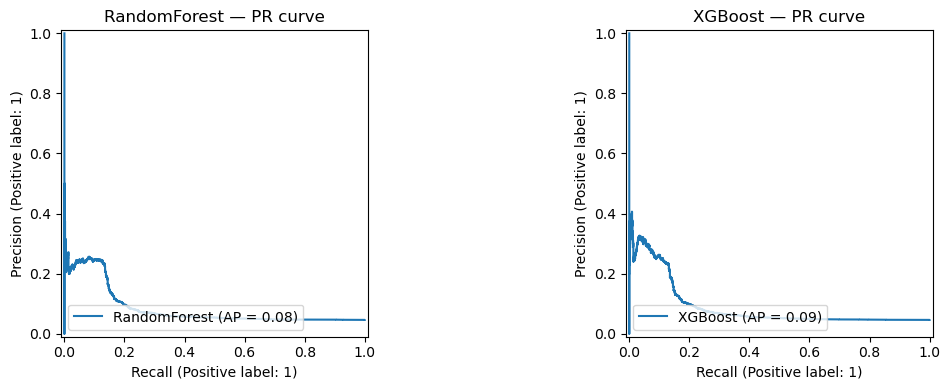

In [31]:
# Precision-Recall curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, model) in zip(axes, [("RandomForest", rf), ("XGBoost", xgb)]):
    y_proba = model.predict_proba(X_test)[:, 1]
    PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=ax, name=name)
    ax.set_title(f"{name} — PR curve")

plt.tight_layout()
plt.show()

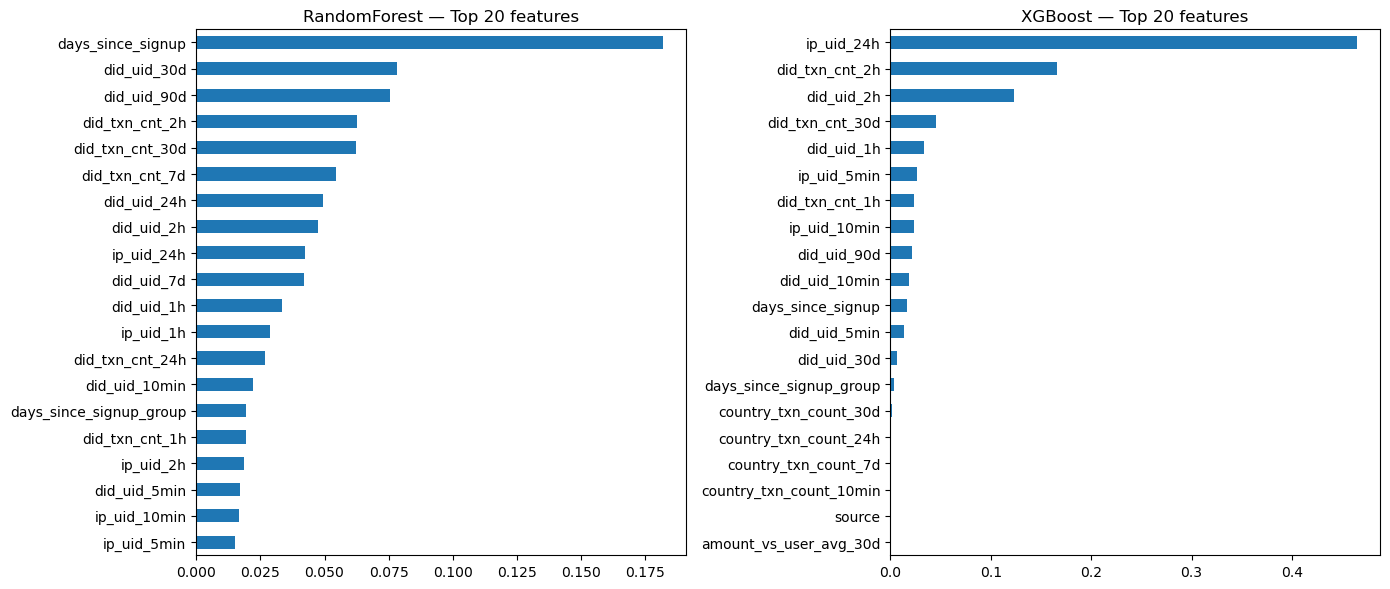

In [32]:
# Feature importances
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (name, model) in zip(axes, [("RandomForest", rf), ("XGBoost", xgb)]):
    importances = pd.Series(model.feature_importances_, index=X_train.columns)
    importances.nlargest(20).sort_values().plot(kind="barh", ax=ax)
    ax.set_title(f"{name} — Top 20 features")

plt.tight_layout()
plt.show()

## Section 6c — Neural Network with Entity Embeddings

Tree models treat every feature as a number. For low-cardinality categoricals like
`browser` (5 values) or `ip_country_code` (~181 countries) that's inefficient — the integer
codes imply a false ordering (e.g. Chrome=0 < IE=1 is meaningless).

Entity embeddings solve this: each category gets a learned dense vector. The network
discovers that, say, certain countries cluster together in embedding space because they
share fraud patterns — without us telling it which ones.

Architecture:
- **Embedding layers** for 9 categorical features → concatenated into a 67-dim vector
- **Concatenate** with 44 scaled continuous features → 111-dim input
- **FC 111→200→100→1** with ReLU + Dropout(0.3)
- **BCEWithLogitsLoss** with `pos_weight=8.5` for class imbalance (same ratio as XGBoost)
- **Adam** optimizer, lr=1e-3, 20 epochs

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

# --- Categorical features (will go through embedding layers) ---
# These have a small, finite number of unique values that carry categorical meaning.
# The model learns a dense vector for each category rather than treating the integer as a number.
CAT_COLS = [
    "sex", "source", "browser", "ip_country_code",
    "hour_of_day", "day_of_week", "month_of_year",
    "age_group", "high_amount_vs_hist",
]

# --- Continuous features (will be scaled then fed directly to FC layers) ---
CONT_COLS = [c for c in X_train.columns if c not in CAT_COLS]

print(f"Categorical ({len(CAT_COLS)}): {CAT_COLS}")
print(f"Continuous  ({len(CONT_COLS)}): {CONT_COLS}")

# Shift features so the minimum index is 0 — nn.Embedding requires non-negative indices.
# sex: -1/0/1 -> 0/1/2 (missing becomes 0)
# ip_country_code: -1 (Unknown) -> 0; all other codes shift up by 1
# month_of_year: 1-12 -> 0-11
X_train_nn = X_train.copy()
X_test_nn  = X_test.copy()
for df_ in [X_train_nn, X_test_nn]:
    df_["sex"]             = df_["sex"]             + 1
    df_["ip_country_code"] = df_["ip_country_code"] + 1
    df_["month_of_year"]   = df_["month_of_year"]   - 1

# Cardinality = max value + 1 after shifting (size of the embedding table).
# Embedding dim formula: int(1.6 * n**0.56), min 2 — from the entity embedding paper.
cardinalities = {col: int(X_train_nn[col].max()) + 1 for col in CAT_COLS}
emb_dims = [(n, max(2, int(1.6 * (n ** 0.56)))) for n in cardinalities.values()]

print(f"\n{'Feature':<22} {'Cardinality':>12} {'Emb dim':>8}")
print("-" * 44)
for col, (n, d) in zip(CAT_COLS, emb_dims):
    print(f"{col:<22} {n:>12} {d:>8}")
print(f"\nTotal embedding output : {sum(d for _, d in emb_dims)}")
print(f"Total continuous       : {len(CONT_COLS)}")
print(f"Total NN input size    : {sum(d for _, d in emb_dims) + len(CONT_COLS)}")


In [ ]:
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

# Scale continuous features — fit ONLY on training data to prevent data leakage.
# Continuous values span very different magnitudes (e.g. purchase_value 9–154,
# purchase_amt_90d 0–10k+). Without scaling, large-magnitude features dominate
# the gradient and the model learns slowly or not at all.
scaler = StandardScaler()
X_train_cont = scaler.fit_transform(X_train_nn[CONT_COLS].values).astype("float32")
X_test_cont  = scaler.transform(X_test_nn[CONT_COLS].values).astype("float32")

X_train_cat  = X_train_nn[CAT_COLS].values.astype("int64")
X_test_cat   = X_test_nn[CAT_COLS].values.astype("int64")
y_train_arr  = y_train.values.astype("float32")
y_test_arr   = y_test.values.astype("float32")

train_ds = TensorDataset(
    torch.from_numpy(X_train_cat),
    torch.from_numpy(X_train_cont),
    torch.from_numpy(y_train_arr).unsqueeze(1),
)
test_ds = TensorDataset(
    torch.from_numpy(X_test_cat),
    torch.from_numpy(X_test_cont),
    torch.from_numpy(y_test_arr).unsqueeze(1),
)

train_loader = DataLoader(train_ds, batch_size=2048, shuffle=True)
test_loader  = DataLoader(test_ds,  batch_size=4096, shuffle=False)

print(f"Train batches: {len(train_loader)} | Test batches: {len(test_loader)}")
print(f"Continuous feature shape: {X_train_cont.shape}")
print(f"Categorical feature shape: {X_train_cat.shape}")

In [ ]:
class FraudNet(nn.Module):
    def __init__(self, emb_dims, n_cont):
        super().__init__()
        # One embedding table per categorical feature
        self.embeddings = nn.ModuleList([nn.Embedding(n, d) for n, d in emb_dims])
        n_emb = sum(d for _, d in emb_dims)

        self.fc1    = nn.Linear(n_emb + n_cont, 200)
        self.fc2    = nn.Linear(200, 100)
        self.output = nn.Linear(100, 1)
        self.relu   = nn.ReLU()
        self.drop   = nn.Dropout(0.3)

    def forward(self, x_cat, x_cont):
        # Look up each categorical in its embedding table and concatenate
        x = torch.cat([e(x_cat[:, i]) for i, e in enumerate(self.embeddings)], dim=1)
        # Append scaled continuous features
        x = torch.cat([x, x_cont], dim=1)
        x = self.drop(self.relu(self.fc1(x)))
        x = self.drop(self.relu(self.fc2(x)))
        # Return raw logit — BCEWithLogitsLoss applies sigmoid internally
        return self.output(x)

In [ ]:
device = torch.device(
    "mps"  if torch.backends.mps.is_available()  else
    "cuda" if torch.cuda.is_available()           else
    "cpu"
)
print(f"Training on: {device}")

nn_model = FraudNet(emb_dims, n_cont=len(CONT_COLS)).to(device)

# BCEWithLogitsLoss applies sigmoid internally (more numerically stable than
# Sigmoid + BCELoss). pos_weight tells it to penalise missing fraud 8.5x harder
# than a false alarm — mirrors scale_pos_weight in XGBoost.
criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([ratio], dtype=torch.float32).to(device))
optimizer = optim.Adam(nn_model.parameters(), lr=1e-3)

print(nn_model)

In [ ]:
print("Training NeuralNet...")
EPOCHS = 20
for epoch in range(1, EPOCHS + 1):
    nn_model.train()
    total_loss = 0.0
    for x_cat_b, x_cont_b, y_b in train_loader:
        x_cat_b  = x_cat_b.to(device)
        x_cont_b = x_cont_b.to(device)
        y_b      = y_b.to(device)
        optimizer.zero_grad()
        loss = criterion(nn_model(x_cat_b, x_cont_b), y_b)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    if epoch % 5 == 0 or epoch == 1:
        nn_model.eval()
        probs = []
        with torch.no_grad():
            for x_cat_b, x_cont_b, _ in test_loader:
                logits = nn_model(x_cat_b.to(device), x_cont_b.to(device))
                probs.extend(torch.sigmoid(logits).cpu().numpy().flatten())
        pr = average_precision_score(y_test, probs)
        print(f"  Epoch {epoch:>3} | loss: {total_loss/len(train_loader):.4f} | PR-AUC: {pr:.4f}")

print("Done!")

In [ ]:
# Final NN evaluation — same metrics as RF/XGBoost for direct comparison
nn_model.eval()
all_proba_nn = []
with torch.no_grad():
    for x_cat_b, x_cont_b, _ in test_loader:
        logits = nn_model(x_cat_b.to(device), x_cont_b.to(device))
        proba = torch.sigmoid(logits).cpu().numpy()
        all_proba_nn.extend(proba.flatten())

y_pred_nn  = (np.array(all_proba_nn) >= 0.5).astype(int)
roc_auc_nn = roc_auc_score(y_test, all_proba_nn)
pr_auc_nn  = average_precision_score(y_test, all_proba_nn)

# Add to results dict so the save cell can compare all three models
results["NeuralNet"] = {"roc_auc": roc_auc_nn, "pr_auc": pr_auc_nn, "model": nn_model}

print(f"\n{'='*40}")
print(f"  NeuralNet")
print(f"{'='*40}")
print(classification_report(y_test, y_pred_nn, target_names=["legit", "fraud"]))
print(f"ROC-AUC : {roc_auc_nn:.4f}")
print(f"PR-AUC  : {pr_auc_nn:.4f}  ← primary metric")
print(f"\nAll models summary:")
for name, r in results.items():
    print(f"  {name:>15}: PR-AUC = {r['pr_auc']:.4f}")

## Section 8 — Save the Best Model

We save:
1. **`model.joblib`** — the trained model object
2. **`model_features.json`** — the exact list of feature column names in training order

The feature list is critical: when `models.py` builds a prediction row from a `Features`
object at inference time, it must use the exact same column order as training.
If they're out of order, the model sees the wrong values for each feature.

In [ ]:
import joblib, json

# Pick the best tree model (RF vs XGBoost) by PR-AUC
tree_results = {k: v for k, v in results.items() if k != "NeuralNet"}
best_name  = max(tree_results, key=lambda k: tree_results[k]["pr_auc"])
best_model = tree_results[best_name]["model"]

print("Model comparison (PR-AUC):")
for name, r in results.items():
    marker = " <- best tree" if name == best_name else ""
    print(f"  {name:>15}: {r['pr_auc']:.4f}{marker}")

# --- Save best tree model ---
joblib.dump(best_model, "../app/decisions/model.joblib")
with open("../app/decisions/model_features.json", "w") as f:
    json.dump(list(X_train.columns), f, indent=2)

# Save country->code mapping so inference can reproduce pd.Categorical codes at runtime.
with open("../app/decisions/ip_country_categories.json", "w") as f:
    json.dump(list(ip_country_cat.categories), f)

print(f"Saved tree model             -> app/decisions/model.joblib")
print(f"Saved ip_country_categories  -> app/decisions/ip_country_categories.json")

# --- Save neural network (only if ALL NN training cells have been run) ---
_nn_ready = 'nn_model' in vars() and 'scaler' in vars() and 'CAT_COLS' in vars()
if _nn_ready:
    torch.save(nn_model.state_dict(), "../app/decisions/model_nn.pt")
    joblib.dump(scaler, "../app/decisions/nn_scaler.joblib")
    with open("../app/decisions/nn_config.json", "w") as f:
        json.dump({
            "cat_cols":  CAT_COLS,
            "cont_cols": CONT_COLS,
            "emb_dims":  emb_dims,
            "shifts": {"sex": 1, "ip_country_code": 1, "month_of_year": -1},
        }, f, indent=2)
    print(f"Saved NN weights             -> app/decisions/model_nn.pt")
    print(f"Saved NN scaler              -> app/decisions/nn_scaler.joblib")
    print(f"Saved NN config              -> app/decisions/nn_config.json")
else:
    print("NN cells not fully run — skipping NN artifact save.")


In [ ]:
# Quick smoke test: load the saved model and make a prediction
loaded = joblib.load("../app/decisions/model.joblib")
with open("../app/decisions/model_features.json") as f:
    feature_names = json.load(f)

# Build a dummy row (all zeros) and predict
dummy = pd.DataFrame([[0] * len(feature_names)], columns=feature_names)
proba = loaded.predict_proba(dummy)[0][1]
print(f"Loaded model OK. Dummy row fraud probability: {proba:.4f}")
print(f"Feature count: {len(feature_names)}")